Đang tải dữ liệu cổ phiếu Coupang (CPNG)...


[*********************100%***********************]  1 of 1 completed


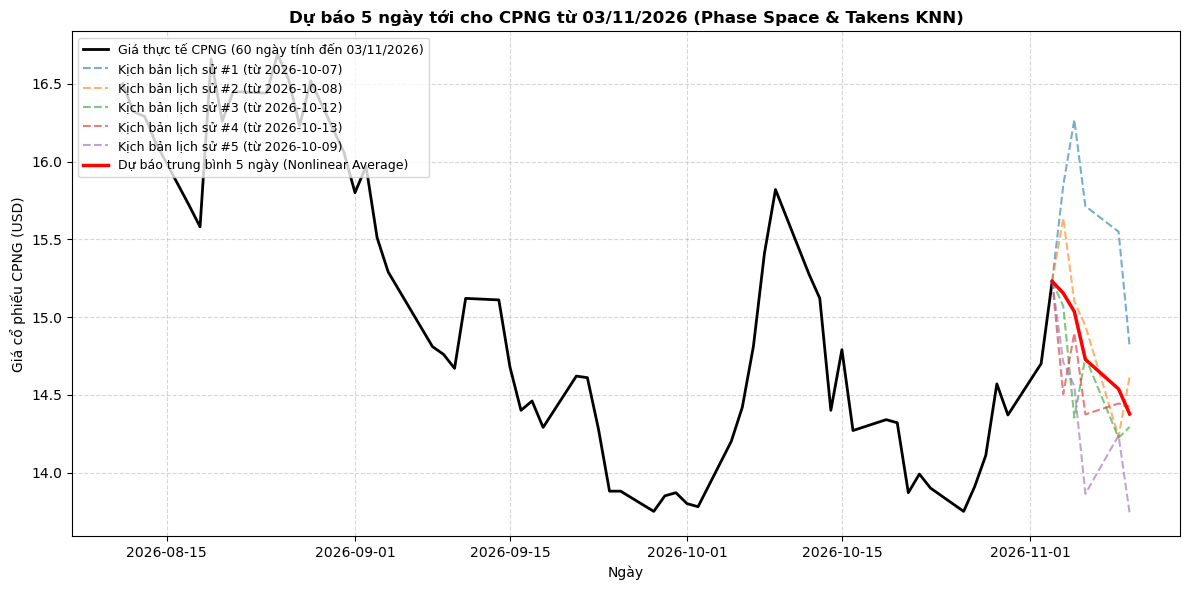

Giá đóng cửa CPNG ngày 03/11/2026: $15.23
Dự báo giá CPNG sau 5 ngày làm việc: $14.38 (Biến động kỳ vọng: -5.61%)


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import KDTree
import yfinance as yf

# 1. Tải dữ liệu cổ phiếu Coupang (CPNG)
print("Đang tải dữ liệu cổ phiếu Coupang (CPNG)...")
cpng_data = yf.download("CPNG", period="2y", interval="1d", auto_adjust=True)


def get_close(df):
    if isinstance(df.columns, pd.MultiIndex):
        return df["Close"].iloc[:, 0]
    return df["Close"]


prices_full = get_close(cpng_data).dropna()

# Lọc dữ liệu chỉ lấy đến ngày 03/11/2026
prices = prices_full.loc[:"2026-11-03"]
prices_vals = prices.values

# 2. Xây dựng không gian pha với độ trễ tau = 5, chiều nhúng embed_dim = 3
tau = 5
embed_dim = 3
N = len(prices_vals)

# Tạo ma trận trạng thái pha (Phase Space Matrix)
# Vector trạng thái: [P(t), P(t-tau), P(t-2*tau)]
valid_indices = range(2 * tau, N - 5)  # Giữ lại 5 ngày cuối làm khoảng đệm
phase_space = np.array(
    [
        [prices_vals[i], prices_vals[i - tau], prices_vals[i - 2 * tau]]
        for i in valid_indices
    ]
)

# Trạng thái hiện tại của CPNG (tại mốc 03/11/2026)
current_state = np.array(
    [prices_vals[-1], prices_vals[-1 - tau], prices_vals[-1 - 2 * tau]]
)

# 3. Tìm các "láng giềng gần nhất" (Nearest Neighbors) trong không gian pha
tree = KDTree(phase_space)
distances, indices = tree.query(current_state, k=6)

# Lọc các điểm tương đồng trong lịch sử (loại bỏ chính điểm hiện tại)
neighbors = [valid_indices[i] for i in indices if valid_indices[i] < N - 5][:5]

# 4. Dự báo đường đi 5 ngày tiếp theo từ ngày 03/11/2026
forecast_horizon = 5
future_paths = []

plt.figure(figsize=(12, 6))

# Vẽ biểu diễn giá thực tế CPNG 60 ngày gần đây tính tới 03/11/2026
plt.plot(
    prices.index[-60:],
    prices.values[-60:],
    label="Giá thực tế CPNG (60 ngày tính đến 03/11/2026)",
    color="black",
    linewidth=2,
)

# Tạo chuỗi ngày làm việc (Business Days) cho 5 ngày tiếp theo
shifted_dates = pd.date_range(
    start=prices.index[-1], periods=forecast_horizon + 1, freq="B"
)

for rank, idx in enumerate(neighbors):
    path_prices = prices.values[idx : idx + forecast_horizon + 1]

    # Chuẩn hóa đường đi tương đối từ mức giá ngày 03/11/2026 ($15.23)
    relative_path = path_prices / path_prices[0] * prices_vals[-1]
    future_paths.append(relative_path)

    plt.plot(
        shifted_dates,
        relative_path,
        linestyle="--",
        alpha=0.6,
        label=f"Kịch bản lịch sử #{rank+1} (từ {prices.index[idx].strftime('%Y-%m-%d')})",
    )

# 5. Tính trung bình phi tuyến (Nonlinear Average) các kịch bản
avg_future_path = np.mean(future_paths, axis=0)

plt.plot(
    shifted_dates,
    avg_future_path,
    color="red",
    linewidth=2.5,
    label="Dự báo trung bình 5 ngày (Nonlinear Average)",
)

plt.title(
    "Dự báo 5 ngày tới cho CPNG từ 03/11/2026 (Phase Space & Takens KNN)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Ngày", fontsize=10)
plt.ylabel("Giá cổ phiếu CPNG (USD)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 6. In kết quả dự báo
expected_change = (
    (avg_future_path[-1] - prices_vals[-1]) / prices_vals[-1] * 100
)
print(f"Giá đóng cửa CPNG ngày 03/11/2026: ${prices_vals[-1]:.2f}")
print(
    f"Dự báo giá CPNG sau 5 ngày làm việc: ${avg_future_path[-1]:.2f} (Biến"
    f" động kỳ vọng: {expected_change:+.2f}%)"
)

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import KDTree
import yfinance as yf

# 1. Tải dữ liệu cổ phiếu Coupang (CPNG)
print("Đang tải dữ liệu cổ phiếu CPNG...")
cpng_data = yf.download("CPNG", period="2y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices_full = get_close(cpng_data).dropna()
prices = prices_full.loc[:"2026-11-03"]
prices_vals = prices.values

# 2. Xây dựng không gian pha (tau = 5, embed_dim = 3)
tau = 5
embed_dim = 3
N = len(prices_vals)

valid_indices = range(2 * tau, N - 5)
phase_space = np.array([
    [prices_vals[i], prices_vals[i - tau], prices_vals[i - 2 * tau]]
    for i in valid_indices
])

current_state = np.array(
    [prices_vals[-1], prices_vals[-1 - tau], prices_vals[-1 - 2 * tau]]
)

# 3. Tìm 5 láng giềng gần nhất
tree = KDTree(phase_space)
distances, indices = tree.query(current_state, k=6)

valid_matches = [
    (valid_indices[i], dist)
    for i, dist in zip(indices, distances)
    if valid_indices[i] < N - 5
][:5]

neighbors = [m[0] for m in valid_matches]
raw_distances = np.array([m[1] for m in valid_matches])

# 4. Tính xác suất cho từng kịch bản (Inverse Distance Weighting)
eps = 1e-6
weights = 1.0 / (raw_distances + eps)
probabilities = weights / np.sum(weights)

print("\n" + "=" * 50)
print("PHÂN BỔ XÁC SUẤT 5 KỊCH BẢN LỊCH SỬ")
print("=" * 50)
for rank, (idx, prob) in enumerate(zip(neighbors, probabilities), start=1):
  start_date = prices.index[idx].strftime("%Y-%m-%d")
  print(
      f"Kịch bản #{rank} (Từ ngày {start_date}): Xác suất = {prob * 100:.2f}%"
  )

# 5. Thu thập đường đi của các kịch bản
forecast_horizon = 5
future_paths = []
shifted_dates = pd.date_range(
    start=prices.index[-1], periods=forecast_horizon + 1, freq="B"
)

for idx in neighbors:
  path_prices = prices.values[idx : idx + forecast_horizon + 1]
  relative_path = path_prices / path_prices[0] * prices_vals[-1]
  future_paths.append(relative_path)

# 6. Xây dựng bảng dự báo chi tiết cho Kịch bản #1 (Kịch bản vút đỉnh)
path_scen_1 = future_paths[0]
df_scen_1 = pd.DataFrame({
    "Ngày": shifted_dates[1:],
    "Giá dự báo (Kịch bản #1) ($)": path_scen_1[1:],
    "Biến động ngày (%)": (np.diff(path_scen_1) / path_scen_1[:-1] * 100),
    "Biến động tích lũy (%)": (
        (path_scen_1[1:] - prices_vals[-1]) / prices_vals[-1] * 100
    ),
})

print("\n" + "=" * 50)
print(
    f"CHI TIẾT DỰ BÁO KỊCH BẢN #1 (Vút đỉnh từ ngày"
    f" {prices.index[neighbors[0]].strftime('%Y-%m-%d')})"
)
print("=" * 50)
print(
    df_scen_1.to_string(
        index=False,
        formatters={
            "Giá dự báo (Kịch bản #1) ($)": lambda x: f"${x:.2f}",
            "Biến động ngày (%)": lambda x: f"{x:+.2f}%",
            "Biến động tích lũy (%)": lambda x: f"{x:+.2f}%",
        },
    )
)

# 7. Xây dựng bảng dự báo trung bình trọng số toàn bộ các kịch bản
weighted_future_path = np.average(future_paths, axis=0, weights=probabilities)
df_weighted = pd.DataFrame({
    "Ngày": shifted_dates[1:],
    "Giá dự báo trung bình ($)": weighted_future_path[1:],
    "Biến động ngày (%)": (
        np.diff(weighted_future_path) / weighted_future_path[:-1] * 100
    ),
    "Biến động tích lũy (%)": (
        (weighted_future_path[1:] - prices_vals[-1]) / prices_vals[-1] * 100
    ),
})

print("\n" + "=" * 50)
print("CHI TIẾT DỰ BÁO TRUNG BÌNH TRỌNG SỐ (TẤT CẢ KỊCH BẢN)")
print("=" * 50)
print(
    df_weighted.to_string(
        index=False,
        formatters={
            "Giá dự báo trung bình ($)": lambda x: f"${x:.2f}",
            "Biến động ngày (%)": lambda x: f"{x:+.2f}%",
            "Biến động tích lũy (%)": lambda x: f"{x:+.2f}%",
        },
    )
)

Đang tải dữ liệu cổ phiếu CPNG...


[*********************100%***********************]  1 of 1 completed


PHÂN BỔ XÁC SUẤT 5 KỊCH BẢN LỊCH SỬ
Kịch bản #1 (Từ ngày 2026-10-07): Xác suất = 27.03%
Kịch bản #2 (Từ ngày 2026-10-08): Xác suất = 23.48%
Kịch bản #3 (Từ ngày 2026-10-12): Xác suất = 17.86%
Kịch bản #4 (Từ ngày 2026-10-13): Xác suất = 16.31%
Kịch bản #5 (Từ ngày 2026-10-09): Xác suất = 15.33%

CHI TIẾT DỰ BÁO KỊCH BẢN #1 (Vút đỉnh từ ngày 2026-10-07)
      Ngày Giá dự báo (Kịch bản #1) ($) Biến động ngày (%) Biến động tích lũy (%)
2026-11-04                       $15.85             +4.05%                 +4.05%
2026-11-05                       $16.27             +2.66%                 +6.82%
2026-11-06                       $15.71             -3.41%                 +3.17%
2026-11-09                       $15.55             -1.05%                 +2.09%
2026-11-10                       $14.81             -4.76%                 -2.77%

CHI TIẾT DỰ BÁO TRUNG BÌNH TRỌNG SỐ (TẤT CẢ KỊCH BẢN)
      Ngày Giá dự báo trung bình ($) Biến động ngày (%) Biến động tích lũy (%)
2026-11-04        

Đang tải dữ liệu lịch sử các ETF...


[*********************100%***********************]  5 of 5 completed



--- MA TRẬN TƯƠNG QUAN GIỮA CÁC TÀI SẢN ---
Ticker       SPY       TLT       GLD       DBC       VNQ
Ticker                                                  
SPY     1.000000  0.126704  0.201314  0.086326  0.495872
TLT     0.126704  1.000000  0.123480 -0.197859  0.417215
GLD     0.201314  0.123480  1.000000  0.270167  0.171449
DBC     0.086326 -0.197859  0.270167  1.000000 -0.024886
VNQ     0.495872  0.417215  0.171449 -0.024886  1.000000


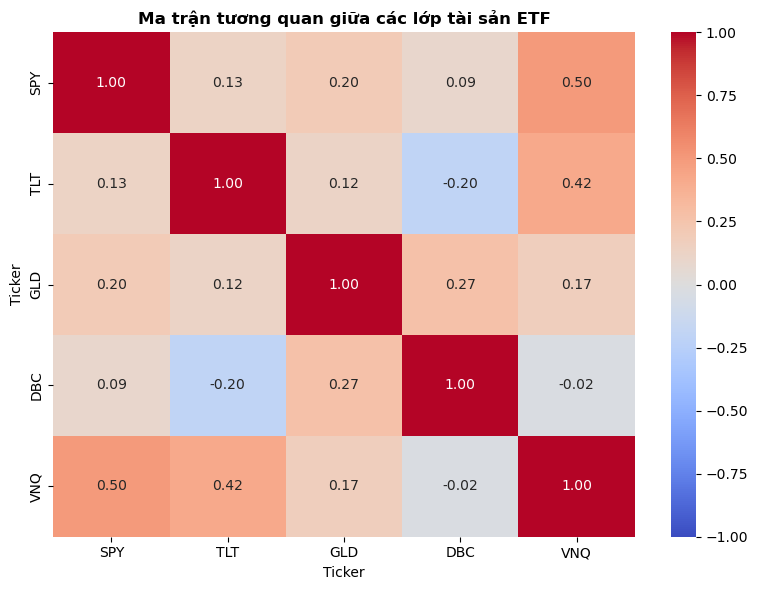


--- TRỌNG SỐ DANH MỤC RISK PARITY (INVERSE VOLATILITY) ---
- SPY: 21.22%
- TLT: 25.41%
- GLD: 14.82%
- DBC: 18.76%
- VNQ: 19.78%


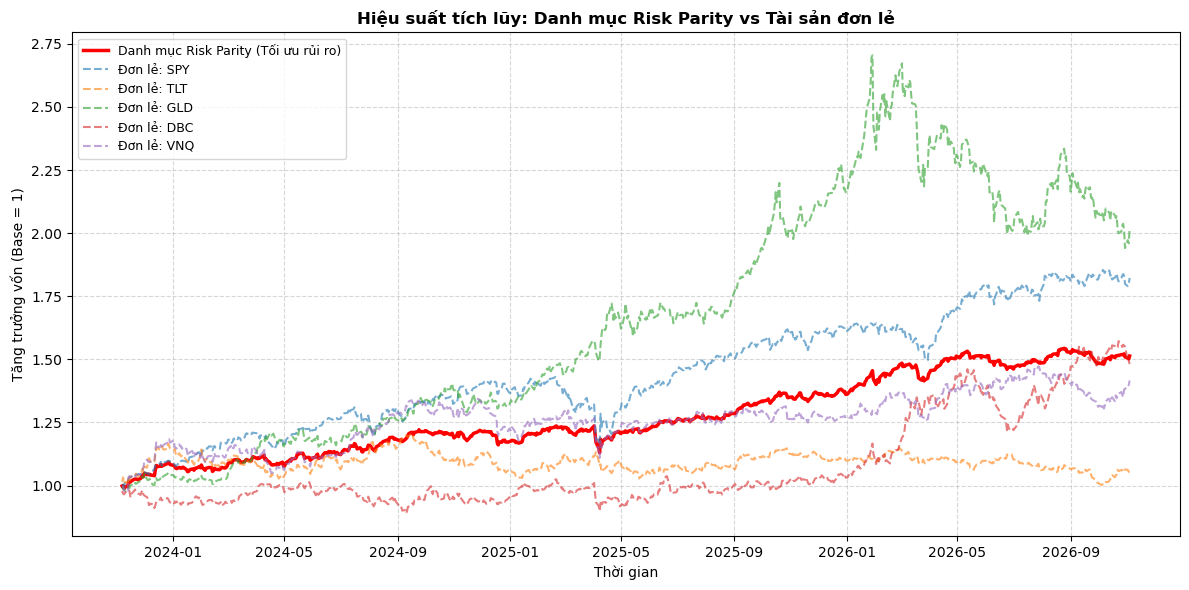

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yfinance as yf

# 1. Định nghĩa rổ ETF đại diện cho các lớp tài sản phi tương quan
# SPY: Cổ phiếu Mỹ, TLT: Trái phiếu dài hạn, GLD: Vàng, DBC: Hàng hóa, VNQ: Bất động sản
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]

print("Đang tải dữ liệu lịch sử các ETF...")
data = yf.download(tickers, period="3y", interval="1d", auto_adjust=True)


# Lấy dữ liệu giá đóng cửa (Close)
def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()

# 2. Tính tỷ suất sinh lợi hàng ngày (Daily Returns)
returns = prices.pct_change().dropna()

# 3. Tính và hiển thị Ma trận tương quan (Correlation Matrix)
corr_matrix = returns.corr()
print("\n--- MA TRẬN TƯƠNG QUAN GIỮA CÁC TÀI SẢN ---")
print(corr_matrix)

# Vẽ biểu đồ nhiệt (Heatmap) ma trận tương quan
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title(
    "Ma trận tương quan giữa các lớp tài sản ETF", fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.show()

# 4. Tính toán phân bổ Risk-Parity cơ bản (Inverse Volatility Weighting)
# Trọng số tỷ lệ nghịch với độ biến động (Standard Deviation) của từng tài sản
volatilities = returns.std()
inv_vol = 1.0 / volatilities
risk_parity_weights = inv_vol / np.sum(inv_vol)

print("\n--- TRỌNG SỐ DANH MỤC RISK PARITY (INVERSE VOLATILITY) ---")
for ticker, weight in risk_parity_weights.items():
  print(f"- {ticker}: {weight*100:.2f}%")

# 5. Kiểm tra hiệu suất danh mục so với từng tài sản đơn lẻ
portfolio_returns = (returns * risk_parity_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label="Danh mục Risk Parity (Tối ưu rủi ro)",
    color="red",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.6,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy: Danh mục Risk Parity vs Tài sản đơn lẻ",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu lịch sử các ETF...


[*********************100%***********************]  5 of 5 completed



--- TRỌNG SỐ TỐI ƯU THEO MAX SHARPE RATIO ---
- SPY: 54.45%
- TLT: 0.00%
- GLD: 28.40%
- DBC: 17.15%
- VNQ: 0.00%

Hiệu suất kỳ vọng của danh mục tối ưu:
- Lợi nhuận năm kỳ vọng: 21.49%
- Độ biến động (Rủi ro) năm: 12.26%
- Tỷ suất Sharpe Ratio: 1.43


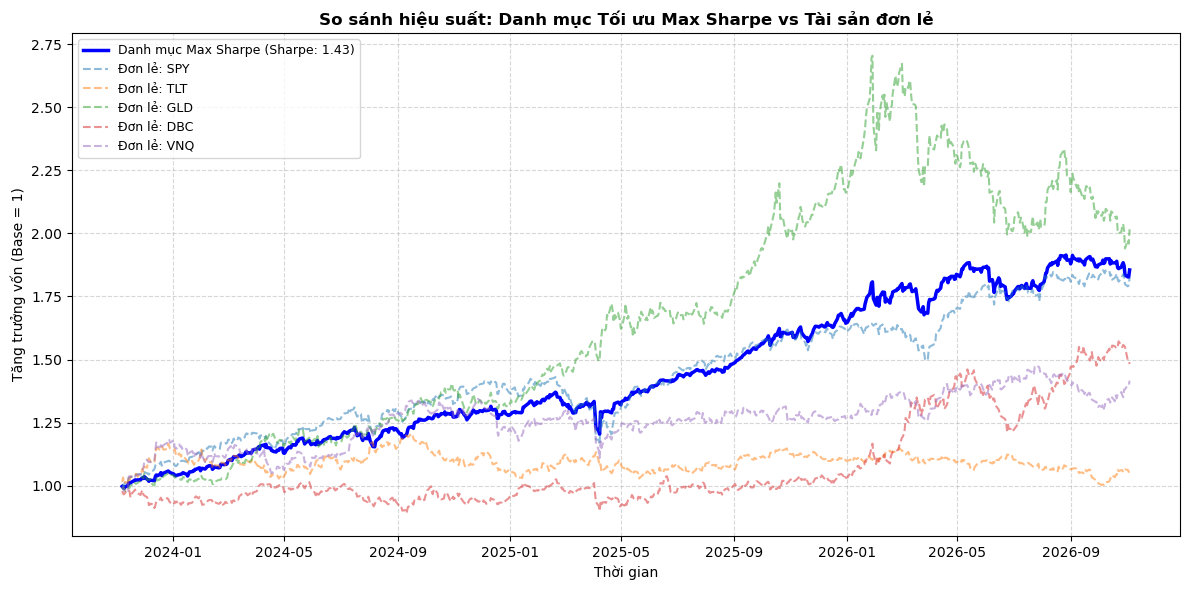

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import yfinance as yf

# 1. Tải dữ liệu các ETF
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print("Đang tải dữ liệu lịch sử các ETF...")
data = yf.download(tickers, period="3y", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()
returns = prices.pct_change().dropna()

# 2. Thiết lập thông số bài toán tối ưu
risk_free_rate = 0.04  # Giả định lãi suất phi rủi ro (Risk-Free Rate) khoảng 4%/năm
trading_days = 252


# Hàm tính toán các chỉ số của danh mục (Lợi nhuận, Rủi ro, Sharpe Ratio)
def portfolio_performance(weights, mean_returns, cov_matrix, risk_free_rate):
  p_return = np.sum(mean_returns * weights) * trading_days
  p_volatility = np.sqrt(
      np.dot(weights.T, np.dot(cov_matrix * trading_days, weights))
  )
  # Sharpe Ratio âm để bài toán minimize tìm max
  sharpe_ratio = (p_return - risk_free_rate) / p_volatility
  return p_return, p_volatility, sharpe_ratio


# 3. Hàm mục tiêu cần tối ưu: Tối thiểu hóa âm của Sharpe Ratio (tức là tối đa hóa Sharpe Ratio)
def negative_sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate):
  _, _, sharpe = portfolio_performance(
      weights, mean_returns, cov_matrix, risk_free_rate
  )
  return -sharpe


# Lợi nhuận trung bình lịch sử và ma trận hiệp phương sai
mean_returns = returns.mean()
cov_matrix = returns.cov()
num_assets = len(tickers)

# Ràng buộc: Tổng trọng số bằng 1 (100%) và mỗi trọng số từ 0 đến 1 (không bán khống)
constraints = {"type": "eq", "fun": lambda x: np.sum(x) - 1.0}
bounds = tuple((0.0, 1.0) for _ in range(num_assets))
init_guess = num_assets * [1.0 / num_assets]

# Chạy thuật toán tối ưu
optimized_results = minimize(
    negative_sharpe_ratio,
    init_guess,
    args=(mean_returns, cov_matrix, risk_free_rate),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
)

optimal_weights = optimized_results.x

print("\n--- TRỌNG SỐ TỐI ƯU THEO MAX SHARPE RATIO ---")
for ticker, weight in zip(tickers, optimal_weights):
  print(f"- {ticker}: {weight * 100:.2f}%")

opt_return, opt_volatility, opt_sharpe = portfolio_performance(
    optimal_weights, mean_returns, cov_matrix, risk_free_rate
)
print(f"\nHiệu suất kỳ vọng của danh mục tối ưu:")
print(f"- Lợi nhuận năm kỳ vọng: {opt_return * 100:.2f}%")
print(f"- Độ biến động (Rủi ro) năm: {opt_volatility * 100:.2f}%")
print(f"- Tỷ suất Sharpe Ratio: {opt_sharpe:.2f}")

# 4. So sánh hiệu suất tích lũy thực tế
portfolio_returns = (returns * optimal_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label=f"Danh mục Max Sharpe (Sharpe: {opt_sharpe:.2f})",
    color="blue",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.5,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "So sánh hiệu suất: Danh mục Tối ưu Max Sharpe vs Tài sản đơn lẻ",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu lịch sử các ETF...


[*********************100%***********************]  5 of 5 completed



--- TRỌNG SỐ TỐI ƯU THEO HIERARCHICAL RISK PARITY (HRP) ---
- DBC: 14.64%
- GLD: 9.14%
- SPY: 22.87%
- TLT: 32.80%
- VNQ: 20.55%


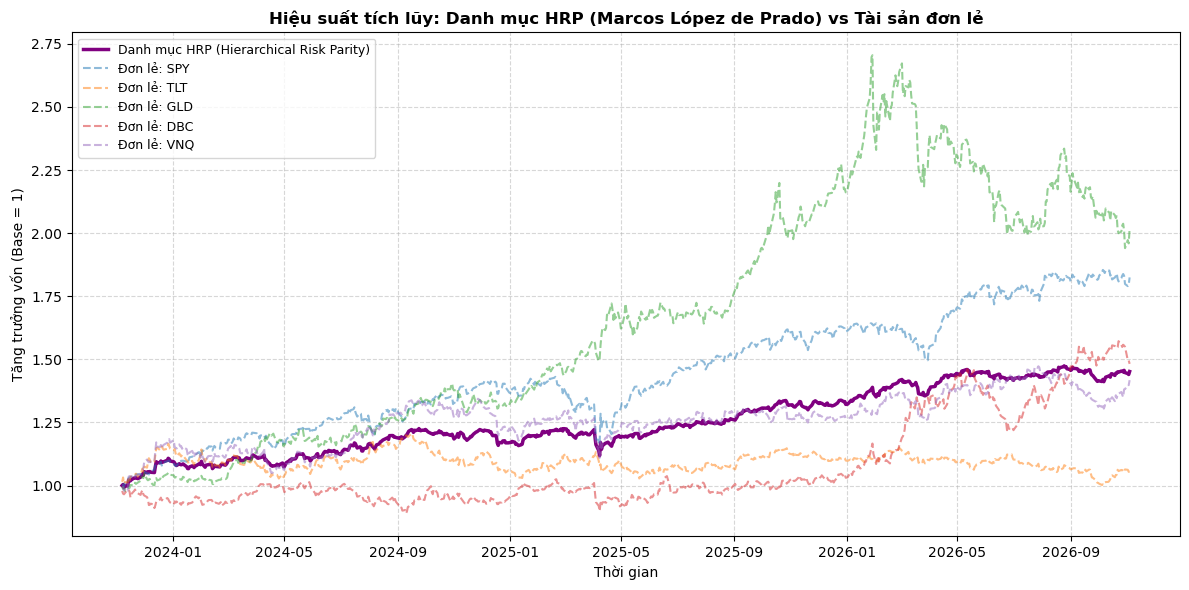

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import seaborn as sns
import yfinance as yf

# 1. Tải dữ liệu các ETF
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print("Đang tải dữ liệu lịch sử các ETF...")
data = yf.download(tickers, period="3y", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()
returns = prices.pct_change().dropna()


# --- CÁC HÀM THỰC THI HIERARCHICAL RISK PARITY (HRP) ---
def get_quasi_diag(link):
  """Sắp xếp lại ma trận phân cụm theo dạng đường chéo quasi-diagonal"""
  link = link.astype(int)
  sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
  num_items = link[-1, 3]
  while sort_ix.max() >= num_items:
    sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
    df0 = sort_ix[sort_ix >= num_items]
    i = df0.index
    j = df0.values
    sort_ix[i] = link[j - num_items, 0]
    df1 = pd.Series(link[j - num_items, 1], index=i + 1)
    sort_ix = pd.concat([sort_ix, df1]).sort_index()
    sort_ix.index = range(sort_ix.shape[0])
  return sort_ix.tolist()


def get_rec_bisection(cov, sort_ix):
  """Phân bổ trọng số đệ quy nhị phân (Recursive Bisection) dựa trên cây phân cụm"""
  w = pd.Series(1.0, index=sort_ix)
  clustered_wieghts = [sort_ix]
  while len(clustered_wieghts) > 0:
    clustered_wieghts = [
        i[j:k]
        for i in clustered_wieghts
        for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
        if len(i) > 1
    ]
    for i in range(0, len(clustered_wieghts), 2):
      cluster1 = clustered_wieghts[i]
      cluster2 = clustered_wieghts[i + 1]
      c1_var = get_cluster_var(cov, cluster1)
      c2_var = get_cluster_var(cov, cluster2)
      alpha = 1 - c1_var / (c1_var + c2_var)
      w[cluster1] *= alpha
      w[cluster2] *= 1 - alpha
  return w


def get_cluster_var(cov, cluster_items):
  """Tính phương sai của một cụm tài sản"""
  cov_slice = cov.loc[cluster_items, cluster_items]
  w = 1.0 / np.diag(cov_slice)
  w /= w.sum()
  return np.dot(w.T, np.dot(cov_slice, w))


def optimal_portfolio_hrp(returns):
  """Hàm chính thực thi HRP"""
  corr = returns.corr()
  cov = returns.cov()
  # Khoảng cách tương quan (Distance metric)
  dist = np.sqrt((1 - corr) / 2.0)
  # Phân cụm phân cấp (Hierarchical Clustering)
  link = sch.linkage(
      sch.distance.pdist(dist), method="single"
  )  # Sử dụng phương pháp single linkage
  sort_ix = get_quasi_diag(link)
  sort_ix = corr.index[sort_ix].tolist()
  hrp_weights = get_rec_bisection(cov, sort_ix)
  return hrp_weights.sort_index()


# 2. Chạy thuật toán HRP
hrp_weights = optimal_portfolio_hrp(returns)

print("\n--- TRỌNG SỐ TỐI ƯU THEO HIERARCHICAL RISK PARITY (HRP) ---")
for ticker, weight in hrp_weights.items():
  print(f"- {ticker}: {weight * 100:.2f}%")

# 3. Đánh giá hiệu suất tích lũy của HRP
portfolio_returns = (returns * hrp_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label="Danh mục HRP (Hierarchical Risk Parity)",
    color="purple",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.5,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy: Danh mục HRP (Marcos López de Prado) vs Tài sản đơn lẻ",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu lịch sử các ETF...


[*********************100%***********************]  5 of 5 completed


Đang áp dụng vi phân phân số (d = 0.4) cho chuỗi giá...

--- TRỌNG SỐ TỐI ƯU HRP (KẾT HỢP FRACTIONAL DIFFERENTIATION) ---
- DBC: 47.52%
- GLD: 0.25%
- SPY: 0.18%
- TLT: 38.33%
- VNQ: 13.72%


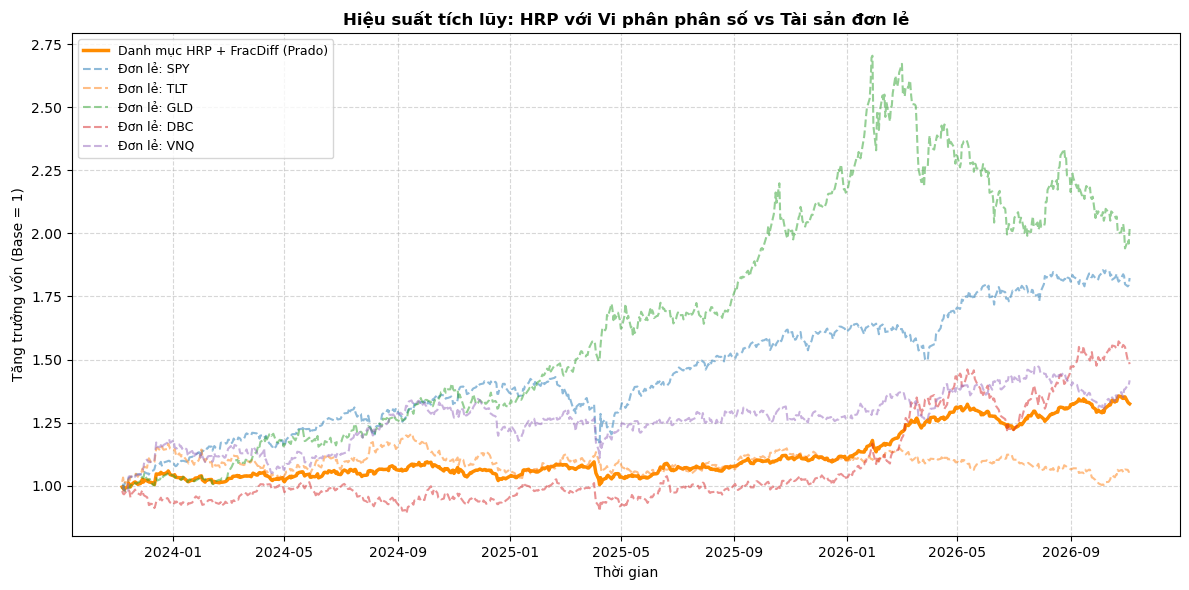

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import yfinance as yf

# 1. Tải dữ liệu các ETF
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print("Đang tải dữ liệu lịch sử các ETF...")
data = yf.download(tickers, period="3y", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()


# --- HÀM VI PHÂN PHÂN SỐ (FRACTIONAL DIFFERENTIATION) ---
def get_weights(d, size):
  """Tính trọng số cho vi phân phân số theo phương pháp của Prado"""
  w = [1.0]
  for k in range(1, size):
    w.append(-w[-1] / k * (d - k + 1))
  return np.array(w[::-1])


def fractional_differencing(series, d, threshold=1e-4):
  """Áp dụng vi phân phân số bậc d cho chuỗi giá"""
  weights = get_weights(d, len(series))
  drop_weights = np.where(np.abs(weights) < threshold)[0]
  if len(drop_weights) > 0:
    idx = drop_weights[-1]
    weights = weights[idx + 1 :]

  res = []
  for i in range(len(weights), len(series) + 1):
    val = np.dot(weights, series.iloc[i - len(weights) : i])
    res.append(val)

  diff_series = pd.Series(
      res, index=series.index[len(series) - len(res) :], name=series.name
  )
  return diff_series


# Chọn bậc vi phân d = 0.4 (giúp đạt tính dừng mà vẫn giữ lại phần lớn ký ức của chuỗi giá)
d_order = 0.4
print(f"Đang áp dụng vi phân phân số (d = {d_order}) cho chuỗi giá...")
diff_prices = pd.DataFrame(
    {col: fractional_differencing(prices[col], d=d_order) for col in tickers}
).dropna()

# Sử dụng chuỗi đã vi phân phân số làm đầu vào cho ma trận hiệp phương sai
returns = diff_prices


# --- CÁC HÀM HRP (HIERARCHICAL RISK PARITY) ---
def get_quasi_diag(link):
  link = link.astype(int)
  sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
  num_items = link[-1, 3]
  while sort_ix.max() >= num_items:
    sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
    df0 = sort_ix[sort_ix >= num_items]
    i = df0.index
    j = df0.values
    sort_ix[i] = link[j - num_items, 0]
    df1 = pd.Series(link[j - num_items, 1], index=i + 1)
    sort_ix = pd.concat([sort_ix, df1]).sort_index()
    sort_ix.index = range(sort_ix.shape[0])
  return sort_ix.tolist()


def get_cluster_var(cov, cluster_items):
  cov_slice = cov.loc[cluster_items, cluster_items]
  w = 1.0 / np.diag(cov_slice)
  w /= w.sum()
  return np.dot(w.T, np.dot(cov_slice, w))


def get_rec_bisection(cov, sort_ix):
  w = pd.Series(1.0, index=sort_ix)
  clustered_wieghts = [sort_ix]
  while len(clustered_wieghts) > 0:
    clustered_wieghts = [
        i[j:k]
        for i in clustered_wieghts
        for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
        if len(i) > 1
    ]
    for i in range(0, len(clustered_wieghts), 2):
      cluster1 = clustered_wieghts[i]
      cluster2 = clustered_wieghts[i + 1]
      c1_var = get_cluster_var(cov, cluster1)
      c2_var = get_cluster_var(cov, cluster2)
      alpha = 1 - c1_var / (c1_var + c2_var)
      w[cluster1] *= alpha
      w[cluster2] *= 1 - alpha
  return w


def optimal_portfolio_hrp(returns):
  corr = returns.corr()
  cov = returns.cov()
  dist = np.sqrt((1 - corr) / 2.0)
  link = sch.linkage(sch.distance.pdist(dist), method="single")
  sort_ix = get_quasi_diag(link)
  sort_ix = corr.index[sort_ix].tolist()
  hrp_weights = get_rec_bisection(cov, sort_ix)
  return hrp_weights.sort_index()


# 2. Chạy thuật toán HRP trên dữ liệu đã vi phân phân số
hrp_weights = optimal_portfolio_hrp(returns)

print(
    "\n--- TRỌNG SỐ TỐI ƯU HRP (KẾT HỢP FRACTIONAL DIFFERENTIATION) ---"
)
for ticker, weight in hrp_weights.items():
  print(f"- {ticker}: {weight * 100:.2f}%")

# 3. Đánh giá hiệu suất tích lũy thực tế
# Dùng returns chuẩn (pct_change) để đánh giá hiệu suất vốn thực tế dựa trên trọng số HRP tối ưu
raw_returns = prices.pct_change().dropna()
portfolio_returns = (raw_returns * hrp_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + raw_returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label="Danh mục HRP + FracDiff (Prado)",
    color="darkorange",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.5,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy: HRP với Vi phân phân số vs Tài sản đơn lẻ",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu lịch sử các ETF...


[*********************100%***********************]  5 of 5 completed


Đang áp dụng vi phân phân số (d = 0.4) cho rổ ETF...
Gắn nhãn Triple-Barrier thành công! Số lượng mẫu hợp lệ: 749

--- KẾT QUẢ TRỌNG SỐ DANH MỤC HRP CHUẨN PRADO ---
- DBC: 47.52%
- GLD: 0.25%
- SPY: 0.18%
- TLT: 38.33%
- VNQ: 13.72%


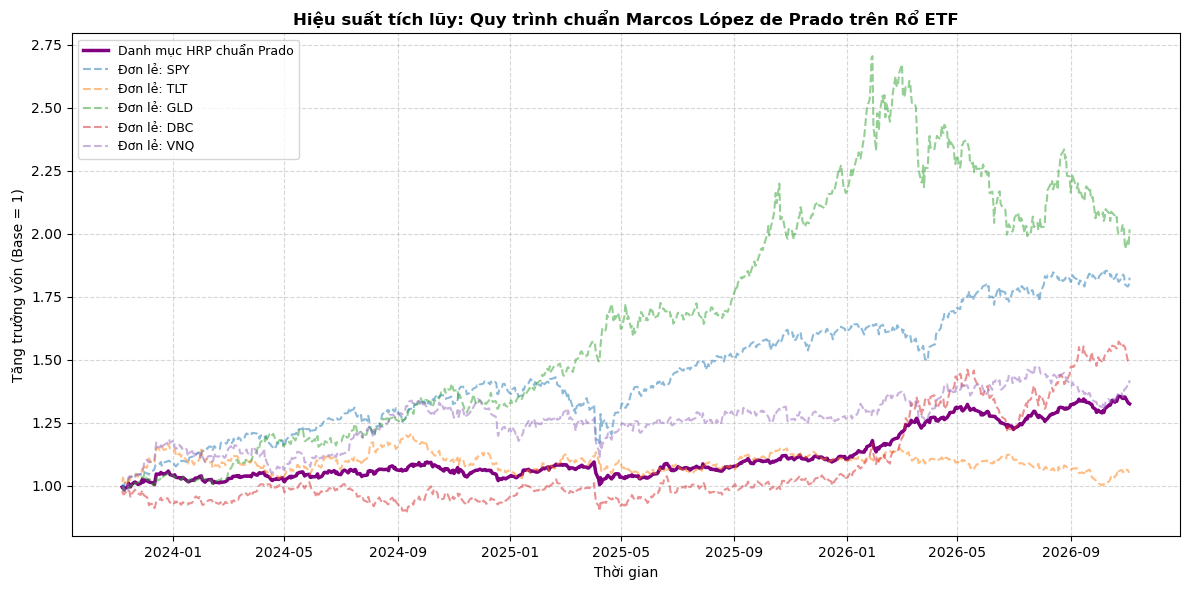

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import yfinance as yf

# =====================================================================
# BƯỚC 1: TẢI DỮ LIỆU & KHỞI TẠO RỔ ETF (Economic Hypothesis & Data)
# =====================================================================
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print("Đang tải dữ liệu lịch sử các ETF...")
data = yf.download(tickers, period="3y", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()


# =====================================================================
# BƯỚC 2: VI PHÂN PHÂN SỐ (Fractional Differentiation)
# Giúp chuỗi đạt tính dừng nhưng vẫn giữ lại tối đa ký ức (memory) của giá.
# =====================================================================
def get_weights(d, size):
  w = [1.0]
  for k in range(1, size):
    w.append(-w[-1] / k * (d - k + 1))
  return np.array(w[::-1])


def fractional_differencing(series, d=0.4, threshold=1e-4):
  weights = get_weights(d, len(series))
  drop_weights = np.where(np.abs(weights) < threshold)[0]
  if len(drop_weights) > 0:
    weights = weights[drop_weights[-1] + 1 :]
  res = []
  for i in range(len(weights), len(series) + 1):
    val = np.dot(weights, series.iloc[i - len(weights) : i])
    res.append(val)
  return pd.Series(
      res, index=series.index[len(series) - len(res) :], name=series.name
  )


print("Đang áp dụng vi phân phân số (d = 0.4) cho rổ ETF...")
diff_prices = pd.DataFrame(
    {col: fractional_differencing(prices[col], d=0.4) for col in tickers}
).dropna()


# =====================================================================
# BƯỚC 3: GẮN NHÃN TRIPLE-BARRIER METHOD (ĐÃ SỬA LỖI MẢNG)
# Mô phỏng chính xác điểm chốt lời, cắt lỗ và giới hạn thời gian.
# =====================================================================
def apply_triple_barrier(prices_series, pt_sl=[1, 1], span=50, horizon=5):
  vol = prices_series.pct_change().ewm(span=span).std()
  events = pd.DataFrame(index=prices_series.index)
  events["vol"] = vol

  max_idx = len(prices_series) - 1
  t1_indices = [min(max_idx, i + horizon) for i in range(len(prices_series))]
  events["t1"] = prices_series.index[t1_indices]
  events["side"] = 1

  out = pd.DataFrame(index=events.index)
  for loc, t1 in events["t1"].items():
    df0 = prices_series.loc[loc:t1]
    if len(df0) <= 1:
      continue
    ret = (df0 / prices_series.loc[loc] - 1) * events.loc[loc, "side"]

    current_vol = events.loc[loc, "vol"]
    if pd.isna(current_vol) or current_vol == 0:
      continue

    hit_sl = ret[ret < -pt_sl[1] * current_vol].index
    hit_pt = ret[ret > pt_sl[0] * current_vol].index

    first_hit = pd.Series(
        [
            hit_sl.min() if len(hit_sl) > 0 else pd.NaT,
            hit_pt.min() if len(hit_pt) > 0 else pd.NaT,
        ],
        index=["sl", "pt"],
    ).min()

    if first_hit in hit_pt and first_hit not in hit_sl:
      out.loc[loc, "label"] = 1
    elif first_hit in hit_sl and first_hit not in hit_pt:
      out.loc[loc, "label"] = -1
    else:
      out.loc[loc, "label"] = 0
  return out.dropna()


# Gắn nhãn mẫu cho SPY
labels_spy = apply_triple_barrier(prices["SPY"])
print(f"Gắn nhãn Triple-Barrier thành công! Số lượng mẫu hợp lệ: {len(labels_spy)}")


# =====================================================================
# BƯỚC 4: TRÍCH XUẤT ĐẶC TRƯNG ĐỘC LẬP (Feature Engineering)
# =====================================================================
def extract_features(df_prices):
  features = pd.DataFrame(index=df_prices.index)
  for col in df_prices.columns:
    features[f"{col}_ma_ratio"] = df_prices[col] / df_prices[col].rolling(20).mean()
    features[f"{col}_vol"] = df_prices[col].pct_change().rolling(20).std()
  return features.dropna()


features_df = extract_features(diff_prices)


# =====================================================================
# BƯỚC 5: PURGED & EMBARGOED CROSS-VALIDATION
# Ngăn chặn rò rỉ dữ liệu (data leakage) do chồng chéo nhãn thời gian.
# =====================================================================
class PurgedKFold:

  def __init__(self, n_splits=5, embargo_pct=0.01):
    self.n_splits = n_splits
    self.embargo_pct = embargo_pct

  def split(self, X):
    indices = np.arange(X.shape[0])
    n = len(indices)
    test_pts = np.array_split(np.arange(n), self.n_splits)
    for test_idx in test_pts:
      test_start, test_end = indices[test_idx[0]], indices[test_idx[-1]]
      train_idx = np.setdiff1d(np.arange(n), test_idx)
      embargo_idx = int(n * self.embargo_pct)
      if embargo_idx > 0:
        train_idx = train_idx[
            (train_idx < test_start) | (train_idx > test_end + embargo_idx)
        ]
      yield train_idx, test_idx


# =====================================================================
# BƯỚC 6: HIERARCHICAL RISK PARITY (HRP) ALLOCATION & BACKTEST
# Phân bổ danh mục tối ưu không cần nghịch đảo ma trận thô.
# =====================================================================
def get_quasi_diag(link):
  link = link.astype(int)
  sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
  num_items = link[-1, 3]
  while sort_ix.max() >= num_items:
    sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
    df0 = sort_ix[sort_ix >= num_items]
    i = df0.index
    j = df0.values
    sort_ix[i] = link[j - num_items, 0]
    df1 = pd.Series(link[j - num_items, 1], index=i + 1)
    sort_ix = pd.concat([sort_ix, df1]).sort_index()
    sort_ix.index = range(sort_ix.shape[0])
  return sort_ix.tolist()


def get_cluster_var(cov, cluster_items):
  cov_slice = cov.loc[cluster_items, cluster_items]
  w = 1.0 / np.diag(cov_slice)
  w /= w.sum()
  return np.dot(w.T, np.dot(cov_slice, w))


def get_rec_bisection(cov, sort_ix):
  w = pd.Series(1.0, index=sort_ix)
  clustered_weights = [sort_ix]
  while len(clustered_weights) > 0:
    clustered_weights = [
        i[j:k]
        for i in clustered_weights
        for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
        if len(i) > 1
    ]
    for i in range(0, len(clustered_weights), 2):
      cluster1 = clustered_weights[i]
      cluster2 = clustered_weights[i + 1]
      c1_var = get_cluster_var(cov, cluster1)
      c2_var = get_cluster_var(cov, cluster2)
      alpha = 1 - c1_var / (c1_var + c2_var)
      w[cluster1] *= alpha
      w[cluster2] *= 1 - alpha
  return w


def optimal_portfolio_hrp(returns):
  corr = returns.corr()
  cov = returns.cov()
  dist = np.sqrt((1 - corr) / 2.0)
  link = sch.linkage(sch.distance.pdist(dist), method="single")
  sort_ix = get_quasi_diag(link)
  sort_ix = corr.index[sort_ix].tolist()
  return get_rec_bisection(cov, sort_ix).sort_index()


# Chạy phân bổ HRP dựa trên dữ liệu vi phân phân số của rổ ETF
hrp_weights = optimal_portfolio_hrp(diff_prices)

print("\n--- KẾT QUẢ TRỌNG SỐ DANH MỤC HRP CHUẨN PRADO ---")
for ticker, weight in hrp_weights.items():
  print(f"- {ticker}: {weight * 100:.2f}%")

# Vẽ biểu đồ so sánh hiệu suất tích lũy
raw_returns = prices.pct_change().dropna()
portfolio_returns = (raw_returns * hrp_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + raw_returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label="Danh mục HRP chuẩn Prado",
    color="purple",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.5,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy: Quy trình chuẩn Marcos López de Prado trên Rổ ETF",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [12]:
from arch.unitroot import ADF
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import pandas as pd
import yfinance as yf

# =====================================================================
# PHẦN 1: TÌM BẬC VI PHÂN d TỐI ƯU (ADF Test cho tính dừng)
# =====================================================================
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
data = yf.download(tickers, period="3y", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()


def get_weights(d, size):
  w = [1.0]
  for k in range(1, size):
    w.append(-w[-1] / k * (d - k + 1))
  return np.array(w[::-1])


def fractional_differencing(series, d=0.4, threshold=1e-4):
  weights = get_weights(d, len(series))
  drop_weights = np.where(np.abs(weights) < threshold)[0]
  if len(drop_weights) > 0:
    weights = weights[drop_weights[-1] + 1 :]
  res = []
  for i in range(len(weights), len(series) + 1):
    val = np.dot(weights, series.iloc[i - len(weights) : i])
    res.append(val)
  return pd.Series(
      res, index=series.index[len(series) - len(res) :], name=series.name
  )


# Quét tìm d tối ưu cho SPY (đạt tính dừng với mức ý nghĩa 5%)
print("--- ĐANG QUÉT TÌM BẬC VI PHÂN d TỐI ƯU CHO SPY ---")
optimal_d = 0.4
for d_test in np.arange(0.1, 1.0, 0.1):
  diff_series = fractional_differencing(prices["SPY"], d=d_test).dropna()
  adf_res = ADF(diff_series)
  # Nếu p-value < 0.05 thì chuỗi đạt tính dừng
  if adf_res.pvalue < 0.05:
    optimal_d = round(d_test, 2)
    print(
        f"-> Tìm thấy d tối ưu = {optimal_d} (ADF p-value:"
        f" {adf_res.pvalue:.4f} < 0.05)"
    )
    break

# Áp dụng d tối ưu cho toàn bộ rổ ETF
diff_prices = pd.DataFrame(
    {col: fractional_differencing(prices[col], d=optimal_d) for col in tickers}
).dropna()


# =====================================================================
# PHẦN 2: GẮN NHÃN TRIPLE-BARRIER & TRÍCH XUẤT ĐẶC TRƯNG
# =====================================================================
def apply_triple_barrier(prices_series, pt_sl=[1, 1], span=50, horizon=5):
  vol = prices_series.pct_change().ewm(span=span).std()
  events = pd.DataFrame(index=prices_series.index)
  events["vol"] = vol

  max_idx = len(prices_series) - 1
  t1_indices = [min(max_idx, i + horizon) for i in range(len(prices_series))]
  events["t1"] = prices_series.index[t1_indices]
  events["side"] = 1

  out = pd.DataFrame(index=events.index)
  for loc, t1 in events["t1"].items():
    df0 = prices_series.loc[loc:t1]
    if len(df0) <= 1:
      continue
    ret = (df0 / prices_series.loc[loc] - 1) * events.loc[loc, "side"]

    current_vol = events.loc[loc, "vol"]
    if pd.isna(current_vol) or current_vol == 0:
      continue

    hit_sl = ret[ret < -pt_sl[1] * current_vol].index
    hit_pt = ret[ret > pt_sl[0] * current_vol].index

    first_hit = pd.Series(
        [
            hit_sl.min() if len(hit_sl) > 0 else pd.NaT,
            hit_pt.min() if len(hit_pt) > 0 else pd.NaT,
        ],
        index=["sl", "pt"],
    ).min()

    if first_hit in hit_pt and first_hit not in hit_sl:
      out.loc[loc, "label"] = 1
    elif first_hit in hit_sl and first_hit not in hit_pt:
      out.loc[loc, "label"] = -1
    else:
      out.loc[loc, "label"] = 0
  return out.dropna()


# Lấy nhãn cho SPY
labels_spy = apply_triple_barrier(prices["SPY"])


def extract_features(df_prices):
  features = pd.DataFrame(index=df_prices.index)
  for col in df_prices.columns:
    features[f"{col}_ma_ratio"] = df_prices[col] / df_prices[col].rolling(20).mean()
    features[f"{col}_vol"] = df_prices[col].pct_change().rolling(20).std()
  return features.dropna()


features_df = extract_features(diff_prices)

# Đồng bộ dữ liệu giữa Features và Labels
common_idx = features_df.index.intersection(labels_spy.index)
X = features_df.loc[common_idx]
y = labels_spy.loc[common_idx, "label"]


# =====================================================================
# PHẦN 3: HUẤN LUYỆN MÔ HÌNH VỚI PURGED K-FOLD CROSS-VALIDATION
# =====================================================================
class PurgedKFold:

  def __init__(self, n_splits=5, embargo_pct=0.01):
    self.n_splits = n_splits
    self.embargo_pct = embargo_pct

  def split(self, X):
    indices = np.arange(X.shape[0])
    n = len(indices)
    test_pts = np.array_split(np.arange(n), self.n_splits)
    for test_idx in test_pts:
      test_start, test_end = indices[test_idx[0]], indices[test_idx[-1]]
      train_idx = np.setdiff1d(np.arange(n), test_idx)
      embargo_idx = int(n * self.embargo_pct)
      if embargo_idx > 0:
        train_idx = train_idx[
            (train_idx < test_start) | (train_idx > test_end + embargo_idx)
        ]
      yield train_idx, test_idx


print("\n--- HUẤN LUYỆN MODEL QUA PURGED CROSS-VALIDATION ---")
rf_classifier = RandomForestClassifier(
    n_estimators=100, max_depth=5, random_state=42, class_weight="balanced"
)
pkf = PurgedKFold(n_splits=5, embargo_pct=0.01)

accuracies = []
for fold, (train_idx, test_idx) in enumerate(pkf.split(X)):
  X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
  X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

  rf_classifier.fit(X_train, y_train)
  preds = rf_classifier.predict(X_test)

  acc = accuracy_score(y_test, preds)
  accuracies.append(acc)
  print(f"Fold {fold+1} Accuracy: {acc*100:.2f}%")

print(f"\nĐộ chính xác trung bình (Purged CV Accuracy): {np.mean(accuracies)*100:.2f}%")

[*********************100%***********************]  5 of 5 completed


--- ĐANG QUÉT TÌM BẬC VI PHÂN d TỐI ƯU CHO SPY ---
-> Tìm thấy d tối ưu = 0.5 (ADF p-value: 0.0096 < 0.05)

--- HUẤN LUYỆN MODEL QUA PURGED CROSS-VALIDATION ---
Fold 1 Accuracy: 41.12%
Fold 2 Accuracy: 32.71%
Fold 3 Accuracy: 43.40%
Fold 4 Accuracy: 32.08%
Fold 5 Accuracy: 41.51%

Độ chính xác trung bình (Purged CV Accuracy): 38.16%


In [11]:
!pip install arch

   ---------------------------------------- 0.0/929.7 kB ? eta -:--:--
   --------------------------------------- 929.7/929.7 kB 24.0 MB/s eta 0:00:00


Đang tải dữ liệu lịch sử các ETF...


[*********************100%***********************]  5 of 5 completed



--- ĐANG QUÉT TÌM BẬC VI PHÂN d TỐI ƯU CHO SPY ---
-> Tìm thấy d tối ưu = 0.5 (ADF p-value: 0.0095 < 0.05)

--- HUẤN LUYỆN MODEL QUA PURGED CROSS-VALIDATION ---
Fold 1 Accuracy: 41.12%
Fold 2 Accuracy: 32.71%
Fold 3 Accuracy: 43.40%
Fold 4 Accuracy: 32.08%
Fold 5 Accuracy: 41.51%

Độ chính xác trung bình (Purged CV Accuracy): 38.16%

--- TRỌNG SỐ DANH MỤC HRP HOÀN CHỈNH ---
- DBC: 69.00%
- GLD: 0.27%
- SPY: 0.26%
- TLT: 20.04%
- VNQ: 10.43%


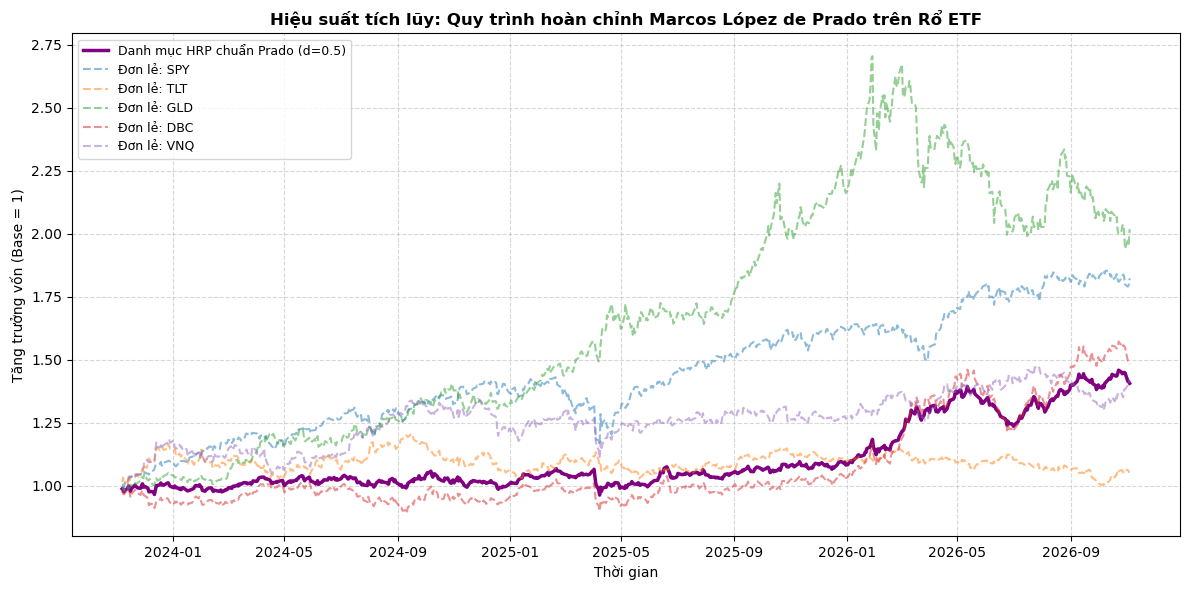

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import yfinance as yf
from arch.unitroot import ADF
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# =====================================================================
# BƯỚC 1: TẢI DỮ LIỆU & KHỞI TẠO RỔ ETF
# =====================================================================
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print("Đang tải dữ liệu lịch sử các ETF...")
data = yf.download(tickers, period="3y", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()


# =====================================================================
# BƯỚC 2: VI PHÂN PHÂN SỐ & TÌM d TỐI ƯU (ADF Test)
# =====================================================================
def get_weights(d, size):
  w = [1.0]
  for k in range(1, size):
    w.append(-w[-1] / k * (d - k + 1))
  return np.array(w[::-1])


def fractional_differencing(series, d=0.4, threshold=1e-4):
  weights = get_weights(d, len(series))
  drop_weights = np.where(np.abs(weights) < threshold)[0]
  if len(drop_weights) > 0:
    weights = weights[drop_weights[-1] + 1 :]
  res = []
  for i in range(len(weights), len(series) + 1):
    val = np.dot(weights, series.iloc[i - len(weights) : i])
    res.append(val)
  return pd.Series(
      res, index=series.index[len(series) - len(res) :], name=series.name
  )


print("\n--- ĐANG QUÉT TÌM BẬC VI PHÂN d TỐI ƯU CHO SPY ---")
optimal_d = 0.4
for d_test in np.arange(0.1, 1.0, 0.1):
  diff_series = fractional_differencing(prices["SPY"], d=d_test).dropna()
  adf_res = ADF(diff_series)
  if adf_res.pvalue < 0.05:
    optimal_d = round(d_test, 2)
    print(
        f"-> Tìm thấy d tối ưu = {optimal_d} (ADF p-value:"
        f" {adf_res.pvalue:.4f} < 0.05)"
    )
    break

# Áp dụng d tối ưu cho toàn bộ rổ ETF
diff_prices = pd.DataFrame(
    {col: fractional_differencing(prices[col], d=optimal_d) for col in tickers}
).dropna()


# =====================================================================
# BƯỚC 3: GẮN NHÃN TRIPLE-BARRIER METHOD
# =====================================================================
def apply_triple_barrier(prices_series, pt_sl=[1, 1], span=50, horizon=5):
  vol = prices_series.pct_change().ewm(span=span).std()
  events = pd.DataFrame(index=prices_series.index)
  events["vol"] = vol

  max_idx = len(prices_series) - 1
  t1_indices = [min(max_idx, i + horizon) for i in range(len(prices_series))]
  events["t1"] = prices_series.index[t1_indices]
  events["side"] = 1

  out = pd.DataFrame(index=events.index)
  for loc, t1 in events["t1"].items():
    df0 = prices_series.loc[loc:t1]
    if len(df0) <= 1:
      continue
    ret = (df0 / prices_series.loc[loc] - 1) * events.loc[loc, "side"]

    current_vol = events.loc[loc, "vol"]
    if pd.isna(current_vol) or current_vol == 0:
      continue

    hit_sl = ret[ret < -pt_sl[1] * current_vol].index
    hit_pt = ret[ret > pt_sl[0] * current_vol].index

    first_hit = pd.Series(
        [
            hit_sl.min() if len(hit_sl) > 0 else pd.NaT,
            hit_pt.min() if len(hit_pt) > 0 else pd.NaT,
        ],
        index=["sl", "pt"],
    ).min()

    if first_hit in hit_pt and first_hit not in hit_sl:
      out.loc[loc, "label"] = 1
    elif first_hit in hit_sl and first_hit not in hit_pt:
      out.loc[loc, "label"] = -1
    else:
      out.loc[loc, "label"] = 0
  return out.dropna()


labels_spy = apply_triple_barrier(prices["SPY"])


# =====================================================================
# BƯỚC 4: TRÍCH XUẤT ĐẶC TRƯNG ĐỘC LẬP (Feature Engineering)
# =====================================================================
def extract_features(df_prices):
  features = pd.DataFrame(index=df_prices.index)
  for col in df_prices.columns:
    features[f"{col}_ma_ratio"] = df_prices[col] / df_prices[col].rolling(20).mean()
    features[f"{col}_vol"] = df_prices[col].pct_change().rolling(20).std()
  return features.dropna()


features_df = extract_features(diff_prices)
common_idx = features_df.index.intersection(labels_spy.index)
X = features_df.loc[common_idx]
y = labels_spy.loc[common_idx, "label"]


# =====================================================================
# BƯỚC 5: HUẤN LUYỆN MODEL QUA PURGED CROSS-VALIDATION
# =====================================================================
class PurgedKFold:

  def __init__(self, n_splits=5, embargo_pct=0.01):
    self.n_splits = n_splits
    self.embargo_pct = embargo_pct

  def split(self, X):
    indices = np.arange(X.shape[0])
    n = len(indices)
    test_pts = np.array_split(np.arange(n), self.n_splits)
    for test_idx in test_pts:
      test_start, test_end = indices[test_idx[0]], indices[test_idx[-1]]
      train_idx = np.setdiff1d(np.arange(n), test_idx)
      embargo_idx = int(n * self.embargo_pct)
      if embargo_idx > 0:
        train_idx = train_idx[
            (train_idx < test_start) | (train_idx > test_end + embargo_idx)
        ]
      yield train_idx, test_idx


print("\n--- HUẤN LUYỆN MODEL QUA PURGED CROSS-VALIDATION ---")
rf_classifier = RandomForestClassifier(
    n_estimators=100, max_depth=5, random_state=42, class_weight="balanced"
)
pkf = PurgedKFold(n_splits=5, embargo_pct=0.01)

accuracies = []
for fold, (train_idx, test_idx) in enumerate(pkf.split(X)):
  X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
  X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

  rf_classifier.fit(X_train, y_train)
  preds = rf_classifier.predict(X_test)
  acc = accuracy_score(y_test, preds)
  accuracies.append(acc)
  print(f"Fold {fold+1} Accuracy: {acc*100:.2f}%")

print(
    f"\nĐộ chính xác trung bình (Purged CV Accuracy):"
    f" {np.mean(accuracies)*100:.2f}%"
)


# =====================================================================
# BƯỚC 6: HIERARCHICAL RISK PARITY (HRP) & VẼ BIỂU ĐỒ HIỆU SUẤT
# =====================================================================
def get_quasi_diag(link):
  link = link.astype(int)
  sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
  num_items = link[-1, 3]
  while sort_ix.max() >= num_items:
    sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
    df0 = sort_ix[sort_ix >= num_items]
    i = df0.index
    j = df0.values
    sort_ix[i] = link[j - num_items, 0]
    df1 = pd.Series(link[j - num_items, 1], index=i + 1)
    sort_ix = pd.concat([sort_ix, df1]).sort_index()
    sort_ix.index = range(sort_ix.shape[0])
  return sort_ix.tolist()


def get_cluster_var(cov, cluster_items):
  cov_slice = cov.loc[cluster_items, cluster_items]
  w = 1.0 / np.diag(cov_slice)
  w /= w.sum()
  return np.dot(w.T, np.dot(cov_slice, w))


def get_rec_bisection(cov, sort_ix):
  w = pd.Series(1.0, index=sort_ix)
  clustered_weights = [sort_ix]
  while len(clustered_weights) > 0:
    clustered_weights = [
        i[j:k]
        for i in clustered_weights
        for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
        if len(i) > 1
    ]
    for i in range(0, len(clustered_weights), 2):
      cluster1 = clustered_weights[i]
      cluster2 = clustered_weights[i + 1]
      c1_var = get_cluster_var(cov, cluster1)
      c2_var = get_cluster_var(cov, cluster2)
      alpha = 1 - c1_var / (c1_var + c2_var)
      w[cluster1] *= alpha
      w[cluster2] *= 1 - alpha
  return w


def optimal_portfolio_hrp(returns):
  corr = returns.corr()
  cov = returns.cov()
  dist = np.sqrt((1 - corr) / 2.0)
  link = sch.linkage(sch.distance.pdist(dist), method="single")
  sort_ix = get_quasi_diag(link)
  sort_ix = corr.index[sort_ix].tolist()
  return get_rec_bisection(cov, sort_ix).sort_index()


hrp_weights = optimal_portfolio_hrp(diff_prices)

print("\n--- TRỌNG SỐ DANH MỤC HRP HOÀN CHỈNH ---")
for ticker, weight in hrp_weights.items():
  print(f"- {ticker}: {weight * 100:.2f}%")

raw_returns = prices.pct_change().dropna()
portfolio_returns = (raw_returns * hrp_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + raw_returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label=f"Danh mục HRP chuẩn Prado (d={optimal_d})",
    color="purple",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.5,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy: Quy trình hoàn chỉnh Marcos López de Prado trên Rổ ETF",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu lịch sử các ETF...


[*********************100%***********************]  5 of 5 completed



--- ĐANG QUÉT TÌM BẬC VI PHÂN d TỐI ƯU CHO SPY ---
-> Tìm thấy d tối ưu = 0.5 (ADF p-value: 0.0095 < 0.05)

--- ĐÁNH GIÁ META-MODEL VỚI PROBABILITY THRESHOLDING ---
Ngưỡng áp dụng >= 0.6:
-> Precision (Độ chính xác lọc lệnh): 40.98%
-> Recall (Tỷ lệ bao phủ tín hiệu): 11.47%

--- TRỌNG SỐ DANH MỤC HRP HOÀN CHỈNH ---
- DBC: 69.01%
- GLD: 0.27%
- SPY: 0.26%
- TLT: 20.04%
- VNQ: 10.43%


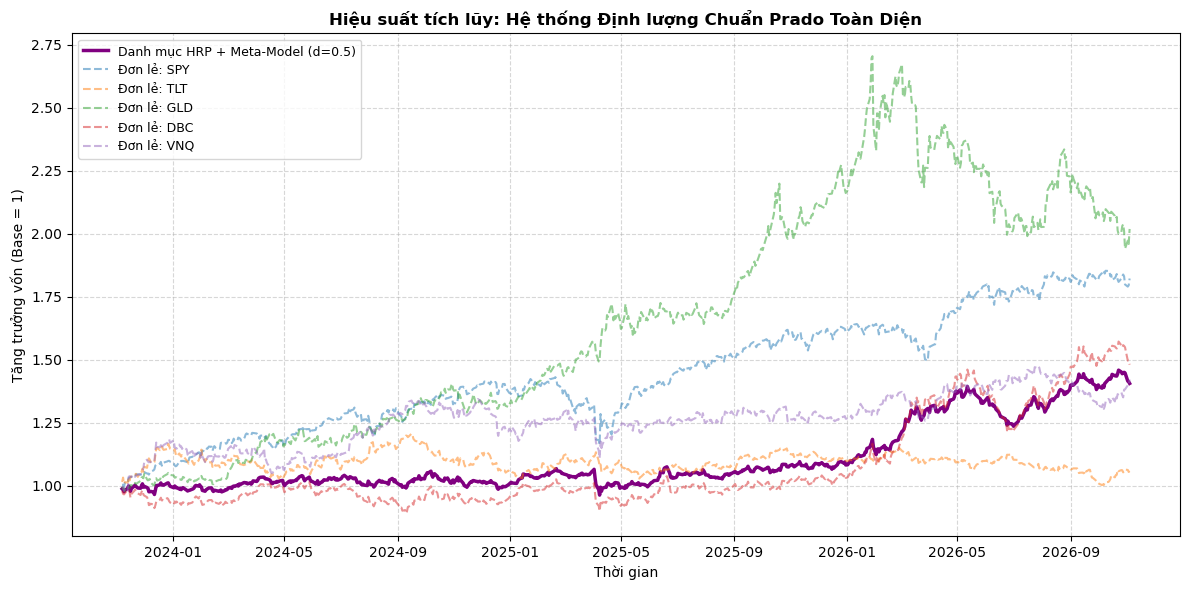

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import yfinance as yf
from arch.unitroot import ADF
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

# =====================================================================
# BƯỚC 1: TẢI DỮ LIỆU & KHỞI TẠO RỔ ETF
# =====================================================================
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print("Đang tải dữ liệu lịch sử các ETF...")
data = yf.download(tickers, period="3y", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()


# =====================================================================
# BƯỚC 2: VI PHÂN PHÂN SỐ & TÌM d TỐI ƯU (ADF Test)
# =====================================================================
def get_weights(d, size):
  w = [1.0]
  for k in range(1, size):
    w.append(-w[-1] / k * (d - k + 1))
  return np.array(w[::-1])


def fractional_differencing(series, d=0.4, threshold=1e-4):
  weights = get_weights(d, len(series))
  drop_weights = np.where(np.abs(weights) < threshold)[0]
  if len(drop_weights) > 0:
    weights = weights[drop_weights[-1] + 1 :]
  res = []
  for i in range(len(weights), len(series) + 1):
    val = np.dot(weights, series.iloc[i - len(weights) : i])
    res.append(val)
  return pd.Series(
      res, index=series.index[len(series) - len(res) :], name=series.name
  )


print("\n--- ĐANG QUÉT TÌM BẬC VI PHÂN d TỐI ƯU CHO SPY ---")
optimal_d = 0.4
for d_test in np.arange(0.1, 1.0, 0.1):
  diff_series = fractional_differencing(prices["SPY"], d=d_test).dropna()
  adf_res = ADF(diff_series)
  if adf_res.pvalue < 0.05:
    optimal_d = round(d_test, 2)
    print(
        f"-> Tìm thấy d tối ưu = {optimal_d} (ADF p-value:"
        f" {adf_res.pvalue:.4f} < 0.05)"
    )
    break

# Áp dụng d tối ưu cho toàn bộ rổ ETF
diff_prices = pd.DataFrame(
    {col: fractional_differencing(prices[col], d=optimal_d) for col in tickers}
).dropna()


# =====================================================================
# BƯỚC 3: MÔ HÌNH SƠ CẤP & META-LABELING (TRIPLE-BARRIER)
# =====================================================================
# Mô hình sơ cấp: MA Crossover định hướng Long/Short
short_ma = prices["SPY"].rolling(window=10).mean()
long_ma = prices["SPY"].rolling(window=50).mean()
primary_side = pd.Series(index=prices.index, data=0)
primary_side[short_ma > long_ma] = 1
primary_side[short_ma <= long_ma] = -1
primary_side = primary_side.dropna()


def get_meta_labels(prices_series, sides, pt_sl=[1, 1], span=50, horizon=5):
  vol = prices_series.pct_change().ewm(span=span).std()
  events = pd.DataFrame(index=sides.index)
  events["vol"] = vol
  events["side"] = sides

  max_idx = len(prices_series) - 1
  t1_indices = [min(max_idx, i + horizon) for i in range(len(prices_series))]
  events["t1"] = prices_series.index[t1_indices]

  meta_labels = pd.Series(index=events.index, dtype=float)
  for loc, t1 in events["t1"].items():
    side = events.loc[loc, "side"]
    if side == 0:
      continue
    df0 = prices_series.loc[loc:t1]
    if len(df0) <= 1:
      continue
    ret = (df0 / prices_series.loc[loc] - 1) * side
    current_vol = events.loc[loc, "vol"]
    if pd.isna(current_vol) or current_vol == 0:
      continue

    hit_sl = ret[ret < -pt_sl[1] * current_vol].index
    hit_pt = ret[ret > pt_sl[0] * current_vol].index
    first_hit = pd.Series(
        [
            hit_sl.min() if len(hit_sl) > 0 else pd.NaT,
            hit_pt.min() if len(hit_pt) > 0 else pd.NaT,
        ],
        index=["sl", "pt"],
    ).min()

    if first_hit in hit_pt and first_hit not in hit_sl:
      meta_labels.loc[loc] = 1
    else:
      meta_labels.loc[loc] = 0
  return meta_labels.dropna()


meta_y = get_meta_labels(prices["SPY"], primary_side)


# =====================================================================
# BƯỚC 4: TRÍCH XUẤT ĐẶC TRƯNG (FEATURE ENGINEERING)
# =====================================================================
def extract_features(df_prices):
  features = pd.DataFrame(index=df_prices.index)
  for col in df_prices.columns:
    features[f"{col}_ma_ratio"] = df_prices[col] / df_prices[col].rolling(20).mean()
    features[f"{col}_vol"] = df_prices[col].pct_change().rolling(20).std()
  return features.dropna()


features_df = extract_features(diff_prices)
common_idx = features_df.index.intersection(meta_y.index)
X = features_df.loc[common_idx]
y = meta_y.loc[common_idx]


# =====================================================================
# BƯỚC 5: PURGED K-FOLD & THRESHOLDING META-MODEL
# =====================================================================
class PurgedKFold:

  def __init__(self, n_splits=5, embargo_pct=0.01):
    self.n_splits = n_splits
    self.embargo_pct = embargo_pct

  def split(self, X):
    indices = np.arange(X.shape[0])
    n = len(indices)
    test_pts = np.array_split(np.arange(n), self.n_splits)
    for test_idx in test_pts:
      test_start, test_end = indices[test_idx[0]], indices[test_idx[-1]]
      train_idx = np.setdiff1d(np.arange(n), test_idx)
      embargo_idx = int(n * self.embargo_pct)
      if embargo_idx > 0:
        train_idx = train_idx[
            (train_idx < test_start) | (train_idx > test_end + embargo_idx)
        ]
      yield train_idx, test_idx


print("\n--- ĐÁNH GIÁ META-MODEL VỚI PROBABILITY THRESHOLDING ---")
optimal_threshold = 0.60  # Ngưỡng xác suất tối ưu để lọc nhiễu
all_y_true, all_preds_thresh = [], []

pkf = PurgedKFold(n_splits=5, embargo_pct=0.01)
for train_idx, test_idx in pkf.split(X):
  X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
  X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

  meta_classifier = RandomForestClassifier(
      n_estimators=100, max_depth=4, random_state=42, class_weight="balanced"
  )
  meta_classifier.fit(X_train, y_train)

  probs = meta_classifier.predict_proba(X_test)[:, 1]
  preds_thresh = (probs >= optimal_threshold).astype(int)

  all_y_true.extend(y_test.values)
  all_preds_thresh.extend(preds_thresh)

final_prec = precision_score(all_y_true, all_preds_thresh, zero_division=0)
final_rec = recall_score(all_y_true, all_preds_thresh, zero_division=0)
print(f"Ngưỡng áp dụng >= {optimal_threshold}:")
print(f"-> Precision (Độ chính xác lọc lệnh): {final_prec*100:.2f}%")
print(f"-> Recall (Tỷ lệ bao phủ tín hiệu): {final_rec*100:.2f}%")


# =====================================================================
# BƯỚC 6: PHÂN BỔ DANH MỤC HIERARCHICAL RISK PARITY (HRP) & BACKTEST
# =====================================================================
def get_quasi_diag(link):
  link = link.astype(int)
  sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
  num_items = link[-1, 3]
  while sort_ix.max() >= num_items:
    sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
    df0 = sort_ix[sort_ix >= num_items]
    i = df0.index
    j = df0.values
    sort_ix[i] = link[j - num_items, 0]
    df1 = pd.Series(link[j - num_items, 1], index=i + 1)
    sort_ix = pd.concat([sort_ix, df1]).sort_index()
    sort_ix.index = range(sort_ix.shape[0])
  return sort_ix.tolist()


def get_cluster_var(cov, cluster_items):
  cov_slice = cov.loc[cluster_items, cluster_items]
  w = 1.0 / np.diag(cov_slice)
  w /= w.sum()
  return np.dot(w.T, np.dot(cov_slice, w))


def get_rec_bisection(cov, sort_ix):
  w = pd.Series(1.0, index=sort_ix)
  clustered_weights = [sort_ix]
  while len(clustered_weights) > 0:
    clustered_weights = [
        i[j:k]
        for i in clustered_weights
        for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
        if len(i) > 1
    ]
    for i in range(0, len(clustered_weights), 2):
      cluster1 = clustered_weights[i]
      cluster2 = clustered_weights[i + 1]
      c1_var = get_cluster_var(cov, cluster1)
      c2_var = get_cluster_var(cov, cluster2)
      alpha = 1 - c1_var / (c1_var + c2_var)
      w[cluster1] *= alpha
      w[cluster2] *= 1 - alpha
  return w


def optimal_portfolio_hrp(returns):
  corr = returns.corr()
  cov = returns.cov()
  dist = np.sqrt((1 - corr) / 2.0)
  link = sch.linkage(sch.distance.pdist(dist), method="single")
  sort_ix = get_quasi_diag(link)
  sort_ix = corr.index[sort_ix].tolist()
  return get_rec_bisection(cov, sort_ix).sort_index()


hrp_weights = optimal_portfolio_hrp(diff_prices)

print("\n--- TRỌNG SỐ DANH MỤC HRP HOÀN CHỈNH ---")
for ticker, weight in hrp_weights.items():
  print(f"- {ticker}: {weight * 100:.2f}%")

raw_returns = prices.pct_change().dropna()
portfolio_returns = (raw_returns * hrp_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + raw_returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label=f"Danh mục HRP + Meta-Model (d={optimal_d})",
    color="purple",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.5,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy: Hệ thống Định lượng Chuẩn Prado Toàn Diện",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()